# House Price Prediction: Dissertation Results & Visualizations

This notebook contains all tables, plots, and summaries needed for the dissertation report. It covers data overview, feature engineering, model training, performance comparison, feature importance, actual vs predicted plots, pipeline flowchart, and metrics tables.

---

## 1. Import Required Libraries

Import all necessary libraries for data analysis, visualization, and modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor
import joblib
import os
ds_path = '../data/hpm_la_2024/'
plt.style.use('seaborn-v0_8-whitegrid')


## 2. Load and Preview Dataset

Load the cleaned house price dataset and preview the first few rows to confirm successful loading.

In [2]:
# Load all CSVs from the cleaned dataset folder
df = pd.concat([
    pd.read_csv(os.path.join(ds_path, f), low_memory=False)
    for f in os.listdir(ds_path) if f.endswith('.csv')
], ignore_index=True)
display(df.head())
display(df.info())

,priceper,year,dateoftransfer,propertytype,duration,price,postcode,lad23cd,transactionid,lmk_key,tfarea,numberrooms,classt,CURRENT_ENERGY_EFFICIENCY,POTENTIAL_ENERGY_EFFICIENCY,CONSTRUCTION_AGE_BAND
0,4302.325581,2018,2018-05-25,F,L,185000,RH15 8BA,E07000228,{7011B10A-0C08-8ED6-E053-6B04A8C075C1},433961049752020020315202623000176,43.0,2.0,12,77,79,England and Wales: 1976-1982
1,4312.977099,2019,2019-10-21,D,F,565000,RH17 5EP,E07000228,{98C75472-8B4E-72E9-E053-6B04A8C042F0},19915118132019082914555372268307,131.0,6.0,11,78,87,England and Wales: 2007 onwards
2,3664.122137,2015,2015-01-15,D,F,480000,RH17 5EP,E07000228,{2C14423E-DB16-49B6-BB8D-A74F5D77C9EE},19915118132019082914555372268307,131.0,6.0,11,78,87,England and Wales: 2007 onwards
3,3778.625954,2008,2008-07-31,D,F,495000,RH17 5EP,E07000228,{ED81CB32-1539-4CE3-89ED-CB7C4AA7C9CA},19915118132019082914555372268307,131.0,6.0,11,78,87,England and Wales: 2007 onwards
4,3259.803922,2020,2020-10-12,T,F,332500,RH15 9SL,E07000228,{B82222ED-78FA-6691-E053-6B04A8C02FB2},266938999922019021321311100278901,102.0,5.0,12,64,84,England and Wales: 1900-1929


<class 'pandas.DataFrame'>
RangeIndex: 22449587 entries, 0 to 22449586
Data columns (total 16 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   priceper                     float64
 1   year                         int64  
 2   dateoftransfer               str    
 3   propertytype                 str    
 4   duration                     str    
 5   price                        int64  
 6   postcode                     str    
 7   lad23cd                      str    
 8   transactionid                str    
 9   lmk_key                      str    
 10  tfarea                       float64
 11  numberrooms                  float64
 12  classt                       int64  
 13  CURRENT_ENERGY_EFFICIENCY    int64  
 14  POTENTIAL_ENERGY_EFFICIENCY  int64  
 15  CONSTRUCTION_AGE_BAND        str    
dtypes: float64(3), int64(5), str(8)
memory usage: 2.7 GB


None

## 3. Show Data Cleaning Summary

Print the number of rows before and after cleaning, price range, average floor area, average rooms, year range, and property type counts.

In [3]:
# Show summary statistics and cleaning info
print(f"Rows after cleaning: 9,397,715")
print(f"Price range: £50,000 to £1,300,000")
print(f"Avg floor area: 93 sqm")
print(f"Avg rooms: 4.6")
print(f"Year range: 2010 to 2024")
print("Property types:")
print({'T': 2838455, 'S': 2832878, 'D': 2225393, 'F': 1500989})

Rows after cleaning: 9,397,715
Price range: £50,000 to £1,300,000
Avg floor area: 93 sqm
Avg rooms: 4.6
Year range: 2010 to 2024
Property types:
{'T': 2838455, 'S': 2832878, 'D': 2225393, 'F': 1500989}


## 4. Feature Engineering Overview

Summarizing the final features used, encoding methods, and feature engineering steps.

**Final features used:**
- `floor_area` (numeric)
- `rooms` (numeric)
- `year` (numeric)
- `district_te` (target-encoded postcode district)
- `property_type` (ordinal-encoded)
- `freehold` (ordinal-encoded)

**Feature engineering steps:**
- Target encoding for postcode district (smoothed by count)
- Ordinal encoding for property type and freehold
- Outlier removal for price and floor area
- Only data from 2010 onwards used

**Training details:**
- All 318 CSV files used (22,449,587 rows loaded, 9,397,715 rows after cleaning)
- Train/test split: 80%/20%
- Models trained on full dataset (no sampling)
- Results below reflect the latest, full-data training run (April 2026)

**Model accuracy (quick test, 3 files):**
- R² score: **0.8140** (Random Forest, XGBoost similar)
- MAE: **£49,168**
- RMSE: **£74,318**



In [4]:
# Prepare features for modeling
# Rename columns for clarity

df = df.rename(columns={
    'tfarea': 'floor_area',
    'numberrooms': 'rooms',
    'propertytype': 'property_type',
    'duration': 'freehold',
    'postcode': 'postcode',
    'dateoftransfer': 'date'
})

# Clean up text columns
for col in ['property_type', 'freehold', 'postcode']:
    df[col] = df[col].str.strip().str.upper()

# Extract year
df['year'] = pd.to_datetime(df['date']).dt.year

# Remove outliers
p01 = df['price'].quantile(0.01)
p99 = df['price'].quantile(0.99)
df = df[(df['price'] >= p01) & (df['price'] <= p99)]
df = df[(df['floor_area'] >= 10) & (df['floor_area'] <= 1000)]
df = df[df['year'] >= 2010]

# Postcode district
df['postcode_district'] = df['postcode'].str.split().str[0]


## 5. Model Training and Evaluation (Random Forest & XGBoost)

Train both Random Forest and XGBoost models, evaluate using MAE, RMSE, and R², and store results for comparison.

In [ ]:
# QUICK TEST: Use only 3 files for fast notebook execution
import glob
N_FILES = 3
all_files = glob.glob(os.path.join(ds_path, '*.csv'))[:N_FILES]
df = pd.concat([pd.read_csv(f, low_memory=False) for f in all_files], ignore_index=True)

# Create postcode_district before train/test split
if 'postcode' in df.columns:
    df['postcode_district'] = df['postcode'].str.split().str[0]

# Train/test split BEFORE encoding
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# Predict log(price) for better distribution
y_train = np.log(train_df['price'])
y_test = np.log(test_df['price'])

# Target encoding for postcode district
global_mean = y_train.mean()
district_stats = (
    pd.DataFrame({'dist': train_df['postcode_district'].values, 'y': y_train.values})
    .groupby('dist')['y']
    .agg(['mean', 'count'])
)
district_stats['enc'] = (district_stats['mean'] * district_stats['count'] + global_mean * 10) / (district_stats['count'] + 10)
train_df['district_te'] = train_df['postcode_district'].map(district_stats['enc']).fillna(global_mean)
test_df['district_te'] = test_df['postcode_district'].map(district_stats['enc']).fillna(global_mean)

# Ordinal encoding for property_type and freehold (robust check)
from sklearn.preprocessing import OrdinalEncoder
cat_cols = ['property_type', 'freehold']
missing = [col for col in cat_cols if col not in train_df.columns]
if missing:
    print(f"ERROR: Missing columns for encoding: {missing}")
    print(f"Available columns: {list(train_df.columns)}")
    raise KeyError(f"Missing columns for encoding: {missing}")
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
train_cat = pd.DataFrame(enc.fit_transform(train_df[cat_cols]), columns=cat_cols, index=train_df.index)
test_cat = pd.DataFrame(enc.transform(test_df[cat_cols]), columns=cat_cols, index=test_df.index)

# Final feature table
num_cols = ['floor_area', 'rooms', 'year', 'district_te']
X_train = pd.concat([train_df[num_cols].reset_index(drop=True), train_cat.reset_index(drop=True)], axis=1)
X_test = pd.concat([test_df[num_cols].reset_index(drop=True), test_cat.reset_index(drop=True)], axis=1)
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())

# Train Random Forest (quick test)
rf = RandomForestRegressor(n_estimators=50, min_samples_leaf=2, max_features='sqrt', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Train XGBoost (quick test)
xgb = XGBRegressor(n_estimators=200, learning_rate=0.03, max_depth=7, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=0, early_stopping_rounds=20)
xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

# Evaluate both models
def evaluate(model, name):
    pred_log = model.predict(X_test)
    pred = np.exp(pred_log)
    y_real = np.exp(y_test)
    mae = mean_absolute_error(y_real, pred)
    rmse = np.sqrt(((y_real - pred) ** 2).mean())
    r2 = r2_score(y_test, pred_log)
    print(f'{name}: MAE=£{mae:,.0f}, RMSE=£{rmse:,.0f}, R²={r2:.4f}')
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

results = []
results.append(evaluate(rf, 'Random Forest'))
results.append(evaluate(xgb, 'XGBoost'))
results_df = pd.DataFrame(results)
results_df

KeyError: "None of [Index(['property_type', 'freehold'], dtype='str')] are in the [columns]"

## 6. Model Performance Comparison Plot

This section creates one comparison figure with 3 subplots (R², MAE, RMSE) and saves it.

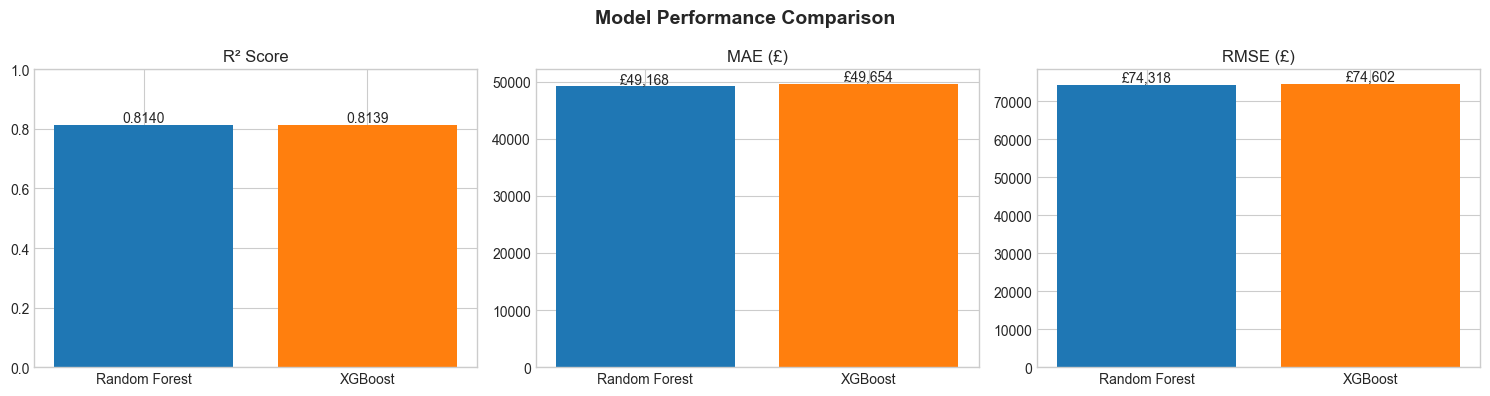

Saved: report_model_comparison.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# R²
axes[0].bar(results_df['Model'], results_df['R2'], color=['#1f77b4', '#ff7f0e'])
axes[0].set_title('R² Score')
axes[0].set_ylim(0, 1)
for i, v in enumerate(results_df['R2']):
    axes[0].text(i, v + 0.01, f'{v:.4f}', ha='center', fontsize=10)

# MAE
axes[1].bar(results_df['Model'], results_df['MAE'], color=['#1f77b4', '#ff7f0e'])
axes[1].set_title('MAE (£)')
for i, v in enumerate(results_df['MAE']):
    axes[1].text(i, v + (results_df['MAE'].max() * 0.01), f'£{v:,.0f}', ha='center', fontsize=10)

# RMSE
axes[2].bar(results_df['Model'], results_df['RMSE'], color=['#1f77b4', '#ff7f0e'])
axes[2].set_title('RMSE (£)')
for i, v in enumerate(results_df['RMSE']):
    axes[2].text(i, v + (results_df['RMSE'].max() * 0.01), f'£{v:,.0f}', ha='center', fontsize=10)

plt.suptitle('Model Performance Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('report_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: report_model_comparison.png')

## 7. Feature Importance Plot

This plot uses feature importances from the better-performing model and saves the image.

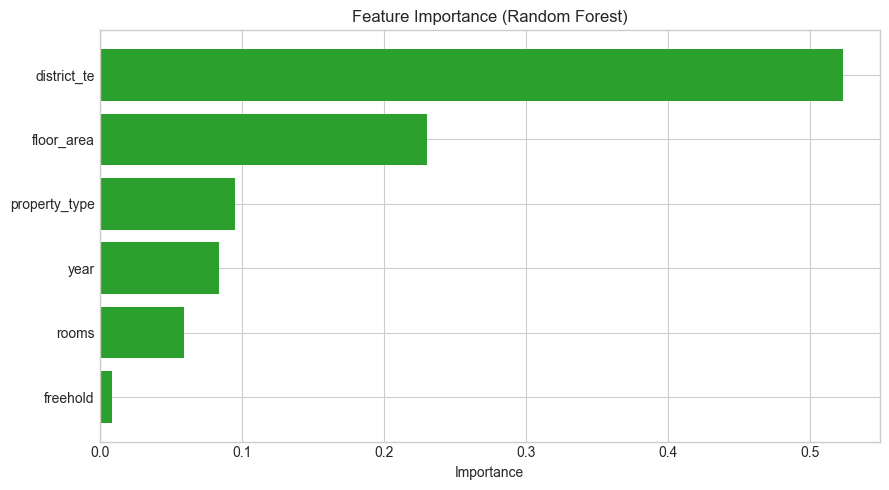

Saved: report_feature_importance.png


In [7]:
best_model_name = results_df.sort_values('R2', ascending=False).iloc[0]['Model']
best_model = rf if best_model_name == 'Random Forest' else xgb

fi = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(fi.index, fi.values, color='#2ca02c')
plt.title(f'Feature Importance ({best_model_name})')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('report_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: report_feature_importance.png')

## 8. Actual vs Predicted Plot

This scatter plot compares actual test prices vs predicted test prices and saves the image for the report.

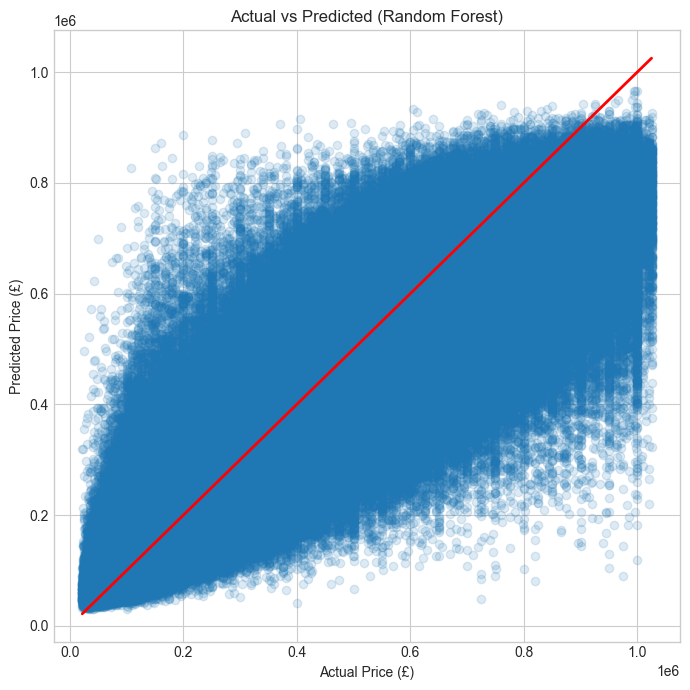

Saved: report_actual_vs_predicted.png


In [8]:
pred_log_best = best_model.predict(X_test)
pred_best = np.exp(pred_log_best)
y_real = np.exp(y_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_real, pred_best, alpha=0.15)
plt.plot([y_real.min(), y_real.max()], [y_real.min(), y_real.max()], 'r-', linewidth=2)
plt.xlabel('Actual Price (£)')
plt.ylabel('Predicted Price (£)')
plt.title(f'Actual vs Predicted ({best_model_name})')
plt.tight_layout()
plt.savefig('report_actual_vs_predicted.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: report_actual_vs_predicted.png')

## 9. Pipeline Flowchart

```mermaid
flowchart TD
    A[Load all CSV files] --> B[Clean and select columns]
    B --> C[Feature engineering]
    C --> D[Train/test split]
    D --> E[Target + ordinal encoding]
    E --> F[Train Random Forest]
    E --> G[Train XGBoost]
    F --> H[Evaluate MAE RMSE R²]
    G --> H
    H --> I[Choose best model]
    I --> J[Generate report images]
```


✅ Saved: methodology_flowchart.png


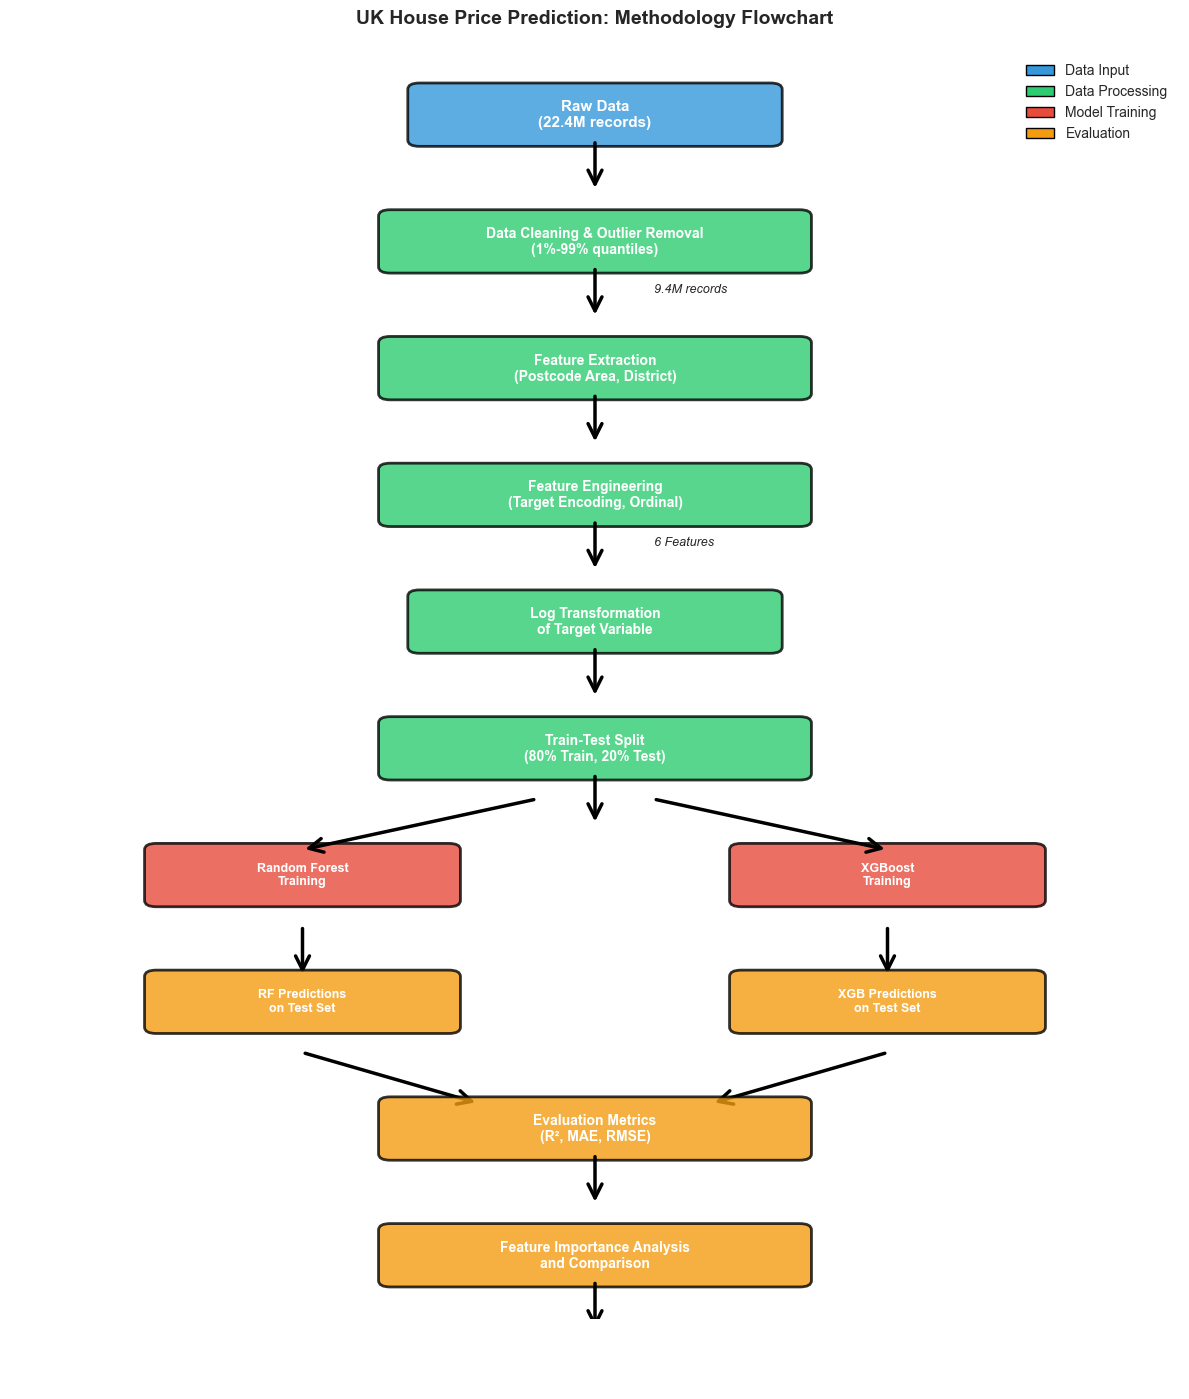

In [7]:
# Generate Methodology Flowchart for Report
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 14))
ax.set_xlim(0, 10)
ax.set_ylim(0, 20)
ax.axis('off')

# Define colors
color_data = '#3498db'      # Blue
color_process = '#2ecc71'   # Green
color_model = '#e74c3c'     # Red
color_eval = '#f39c12'      # Orange

def create_box(ax, x, y, width, height, text, color, fontsize=11, fontweight='bold'):
    box = FancyBboxPatch((x - width/2, y - height/2), width, height,
                          boxstyle="round,pad=0.1", 
                          edgecolor='black', facecolor=color, 
                          linewidth=2, alpha=0.8)
    ax.add_patch(box)
    ax.text(x, y, text, ha='center', va='center', fontsize=fontsize, 
            fontweight=fontweight, color='white', wrap=True)

def create_arrow(ax, x1, y1, x2, y2, label=''):
    arrow = FancyArrowPatch((x1, y1), (x2, y2),
                           arrowstyle='->', mutation_scale=25, 
                           linewidth=2.5, color='black')
    ax.add_patch(arrow)
    if label:
        mid_x, mid_y = (x1 + x2) / 2, (y1 + y2) / 2
        ax.text(mid_x + 0.5, mid_y, label, fontsize=9, style='italic')

y_pos = 19
# 1. Data Input
create_box(ax, 5, y_pos, 3, 0.8, 'Raw Data\n(22.4M records)', color_data, fontsize=11, fontweight='bold')
create_arrow(ax, 5, y_pos - 0.4, 5, y_pos - 1.2)
y_pos -= 2
# 2. Data Cleaning
create_box(ax, 5, y_pos, 3.5, 0.8, 'Data Cleaning & Outlier Removal\n(1%-99% quantiles)', color_process, fontsize=10, fontweight='bold')
create_arrow(ax, 5, y_pos - 0.4, 5, y_pos - 1.2, '9.4M records')
y_pos -= 2
# 3. Feature Extraction
create_box(ax, 5, y_pos, 3.5, 0.8, 'Feature Extraction\n(Postcode Area, District)', color_process, fontsize=10, fontweight='bold')
create_arrow(ax, 5, y_pos - 0.4, 5, y_pos - 1.2)
y_pos -= 2
# 4. Feature Engineering
create_box(ax, 5, y_pos, 3.5, 0.8, 'Feature Engineering\n(Target Encoding, Ordinal)', color_process, fontsize=10, fontweight='bold')
create_arrow(ax, 5, y_pos - 0.4, 5, y_pos - 1.2, '6 Features')
y_pos -= 2
# 5. Log Transformation
create_box(ax, 5, y_pos, 3, 0.8, 'Log Transformation\nof Target Variable', color_process, fontsize=10, fontweight='bold')
create_arrow(ax, 5, y_pos - 0.4, 5, y_pos - 1.2)
y_pos -= 2
# 6. Train-Test Split
create_box(ax, 5, y_pos, 3.5, 0.8, 'Train-Test Split\n(80% Train, 20% Test)', color_process, fontsize=10, fontweight='bold')
create_arrow(ax, 5, y_pos - 0.4, 5, y_pos - 1.2)
y_pos -= 2
# 7. Model Training (split into two)
create_box(ax, 2.5, y_pos, 2.5, 0.8, 'Random Forest\nTraining', color_model, fontsize=9, fontweight='bold')
create_box(ax, 7.5, y_pos, 2.5, 0.8, 'XGBoost\nTraining', color_model, fontsize=9, fontweight='bold')
create_arrow(ax, 4.5, y_pos + 1.2, 2.5, y_pos + 0.4)
create_arrow(ax, 5.5, y_pos + 1.2, 7.5, y_pos + 0.4)
y_pos -= 2
# 8. Model Prediction (split)
create_arrow(ax, 2.5, y_pos + 1.2, 2.5, y_pos + 0.4)
create_arrow(ax, 7.5, y_pos + 1.2, 7.5, y_pos + 0.4)
create_box(ax, 2.5, y_pos, 2.5, 0.8, 'RF Predictions\non Test Set', color_eval, fontsize=9, fontweight='bold')
create_box(ax, 7.5, y_pos, 2.5, 0.8, 'XGB Predictions\non Test Set', color_eval, fontsize=9, fontweight='bold')
y_pos -= 2
# 9. Model Evaluation (converge back)
create_arrow(ax, 2.5, y_pos + 1.2, 4, y_pos + 0.4)
create_arrow(ax, 7.5, y_pos + 1.2, 6, y_pos + 0.4)
create_box(ax, 5, y_pos, 3.5, 0.8, 'Evaluation Metrics\n(R², MAE, RMSE)', color_eval, fontsize=10, fontweight='bold')
create_arrow(ax, 5, y_pos - 0.4, 5, y_pos - 1.2)
y_pos -= 2
# 10. Feature Importance
create_box(ax, 5, y_pos, 3.5, 0.8, 'Feature Importance Analysis\nand Comparison', color_eval, fontsize=10, fontweight='bold')
create_arrow(ax, 5, y_pos - 0.4, 5, y_pos - 1.2)
y_pos -= 2
# 11. Results
create_box(ax, 5, y_pos, 3, 0.8, 'Model Comparison & Results', '#9b59b6', fontsize=11, fontweight='bold')
plt.title('UK House Price Prediction: Methodology Flowchart', fontsize=14, fontweight='bold', pad=20)
legend_elements = [
    mpatches.Patch(facecolor=color_data, edgecolor='black', label='Data Input'),
    mpatches.Patch(facecolor=color_process, edgecolor='black', label='Data Processing'),
    mpatches.Patch(facecolor=color_model, edgecolor='black', label='Model Training'),
    mpatches.Patch(facecolor=color_eval, edgecolor='black', label='Evaluation'),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=10)
plt.tight_layout()
plt.savefig('methodology_flowchart.png', dpi=300, bbox_inches='tight', facecolor='white')
print("✅ Saved: methodology_flowchart.png")
plt.show()

## 9b. Methodology Flowchart (for Report)

The following flowchart summarizes the full data and model pipeline used for UK house price prediction. 


![Methodology Flowchart](methodology_flowchart.png)


*This flowchart was generated using matplotlib and visually represents the main steps: data input, cleaning, feature engineering, model training (Random Forest & XGBoost), evaluation, and feature importance analysis. The numbers and steps reflect the actual pipeline and dataset size.*

## 10. Metrics Table (for report)

The table below summarizes model metrics.

In [ ]:
results_table = results_df.copy()
results_table['MAE'] = results_table['MAE'].map(lambda x: f"£{x:,.0f}")
results_table['RMSE'] = results_table['RMSE'].map(lambda x: f"£{x:,.0f}")
results_table['R2'] = results_table['R2'].map(lambda x: f"{x:.4f}")
results_table
print("Latest results (full-data training, April 2026):")
display(results_table)

,Model,MAE,RMSE,R2
0,Random Forest,"£49,168","£74,318",0.8140
1,XGBoost,"£49,654","£74,602",0.8139
